# Reproducing Figure 1(a)-(c) of Zhang et al. (ICLR 2017)

Paper: *Understanding Deep Learning Requires Rethinking Generalization*. This notebook reproduces, on CIFAR-10:

- **Figure 1(a)**: training loss curves for small Inception under five conditions (true labels, random labels, shuffled pixels, random pixels, Gaussian);
- **Figure 1(b)**: for three models (small Inception, small AlexNet, MLP 1x512), the time needed to fit the training set at label corruption level $p$, relative to $p=0$;
- **Figure 1(c)**: the test error of those same runs after training stops.

**How to run**

1. *Runtime -> Change runtime type*, select **GPU** (a T4 is enough).
2. *Runtime -> Run all*. The first run asks for Google Drive authorization; everything is stored under `MyDrive/zhang2017_repro/`.
3. **After a disconnect**: reconnect to a GPU and *Run all* again. Finished experiments are skipped, and an unfinished one resumes from its last checkpoint.
4. The last few cells produce the figures and tables. You can run them on their own at any point; they plot whatever results already exist.

**Note**: results are keyed by experiment name. If you change the configuration (batch size, say) and want to rerun, point `ROOT` at a new folder, otherwise the old results will be treated as finished and skipped.

## 1. Environment and output paths

In [4]:
import os, json, time, math, glob
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
import pandas as pd

try:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = '/content/drive/MyDrive/zhang2017_repro'
    DATA_DIR = '/content/data'          # keep the dataset on local disk, it reads faster
except ImportError:                     # outside Colab, write to the current directory
    ROOT = './zhang2017_repro'
    DATA_DIR = './data'

RESULT_DIR = os.path.join(ROOT, 'results')
CKPT_DIR = os.path.join(ROOT, 'checkpoints')
FIG_DIR = os.path.join(ROOT, 'figures')
for d in (RESULT_DIR, CKPT_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cuda':
    torch.backends.cudnn.benchmark = True
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('No GPU found. Training will be very slow. Select GPU under Runtime -> Change runtime type.')
print('torch', torch.__version__, '| results go to', ROOT)

Mounted at /content/drive
No GPU found. Training will be very slow. Select GPU under Runtime -> Change runtime type.
torch 2.11.0+cpu | results go to /content/drive/MyDrive/zhang2017_repro


## 2. Configuration

The first block is what the paper reports in Appendix A. The second block is what the paper does **not** report and we had to choose ourselves; these belong in the setup table of the report.

In [2]:
# ---- settings taken from the paper (Appendix A) ----
LR0 = {'inception': 0.1, 'alexnet': 0.01, 'mlp1x512': 0.01}   # initial learning rate
MOMENTUM = 0.9
LR_DECAY = 0.95          # learning rate is multiplied by 0.95 after every epoch
WEIGHT_DECAY = 0.0       # Figure 1 uses no explicit regularization (no weight decay, dropout or augmentation)
NUM_CLASSES = 10

# ---- settings the paper does not report, chosen by us ----
BATCH_SIZE = 128
MAX_EPOCHS = 100         # hard cap on epochs per experiment
FIT_ACC = 0.99           # first time train accuracy reaches this, the run counts as "fitted" (used by Figure 1b)
STOP_ACC = 0.999         # stop training once train accuracy reaches this
PLATEAU_PATIENCE = 15    # also stop if train accuracy has not improved for this many epochs
DATA_SEED = 0            # controls label corruption, pixel permutations and Gaussian inputs
MODEL_SEED = 0           # controls initialization and mini-batch order
USE_AMP = True           # mixed precision (GPU only), much faster
LOG_EVERY = 100          # record the running mean training loss every N steps (used by Figure 1a)
CKPT_EVERY = 5           # write a checkpoint every N epochs, so a disconnect can be resumed
EVAL_BATCH = 1000

# ---- which experiments to run ----
QUICK = False            # True: p takes only 0, 0.2, ..., 1.0, which roughly halves the total time
P_GRID = [round(0.2 * i, 1) for i in range(6)] if QUICK else [round(0.1 * i, 1) for i in range(11)]
MODELS = ['mlp1x512', 'alexnet', 'inception']
FIG1A_INPUTS = ['shuffled_pixels', 'random_pixels', 'gaussian']

FAKE_DATA = False        # only for debugging the code without network access; keep False for real runs

## 3. Data

Preprocessing follows Appendix A: divide pixels by 255 -> center crop from 32x32 to 28x28 -> per-image whitening (TensorFlow's `per_image_whitening`: subtract each image's own mean, divide by $\max(\text{std}, 1/\sqrt{2352})$). So the input dimension is $d = 28\times28\times3 = 2352$.

The whole dataset is kept on the GPU (the training set is about 470 MB), with no DataLoader, which is considerably faster.

In [3]:
def load_cifar10():
    # returns raw 32x32 images in [0,1] plus labels
    if FAKE_DATA:
        g = torch.Generator().manual_seed(0)
        xtr = torch.rand(512, 3, 32, 32, generator=g); ytr = torch.randint(0, 10, (512,), generator=g)
        xte = torch.rand(256, 3, 32, 32, generator=g); yte = torch.randint(0, 10, (256,), generator=g)
        return xtr, ytr, xte, yte
    tr = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True)
    te = torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=True)
    to_x = lambda d: torch.from_numpy(d.data).permute(0, 3, 1, 2).float().div_(255.0)
    return to_x(tr), torch.tensor(tr.targets), to_x(te), torch.tensor(te.targets)


def center_crop(x, size=28):
    off = (x.shape[-1] - size) // 2
    return x[..., off:off + size, off:off + size].contiguous()


def per_image_whiten(x):
    # subtract each image's own mean, divide by max(std, 1/sqrt(number of pixels))
    flat = x.reshape(x.shape[0], -1)
    mean = flat.mean(dim=1, keepdim=True)
    std = flat.std(dim=1, unbiased=False, keepdim=True)
    std = torch.clamp(std, min=1.0 / math.sqrt(flat.shape[1]))
    return ((flat - mean) / std).reshape(x.shape)


XTR_RAW, YTR_TRUE, XTE_RAW, YTE = load_cifar10()
XTR_RAW, XTE_RAW = center_crop(XTR_RAW), center_crop(XTE_RAW)
print('train', tuple(XTR_RAW.shape), '| test', tuple(XTE_RAW.shape))

100%|██████████| 170M/170M [55:12<00:00, 51.5kB/s]


train (50000, 3, 28, 28) | test (10000, 3, 28, 28)


### 3.1 The six randomization conditions

- **Labels**: with probability $p$, a training label is replaced by a class drawn **uniformly** from the 10 classes (which may be the original class again); otherwise it is left alone. $p=0$ is true labels and $p=1$ is random labels. The corrupted labels are drawn **once** and stay the same in every epoch (paper, Section 2.1 and Appendix A). Test labels are never corrupted.
- **shuffled pixels**: one fixed permutation of pixel positions, applied to every image in both the training and the test set.
- **random pixels**: each image gets its own independent permutation.
- **Gaussian**: every pixel is sampled independently from a Gaussian whose mean and variance match the training set, per channel.

The paper does not say whether the permutations also shuffle the color channels. Here only positions are permuted, and the RGB values of a pixel move together. Labels stay true in all three input conditions.

In [4]:
INPUT_CONDITIONS = ['natural', 'shuffled_pixels', 'random_pixels', 'gaussian']


def make_inputs(condition, seed=DATA_SEED):
    # apply the same transformation to the training and test set, then whiten per image
    g = torch.Generator().manual_seed(seed + 12345)
    C, H, W = XTR_RAW.shape[1:]

    if condition == 'natural':
        f = lambda x: x
    elif condition == 'shuffled_pixels':
        perm = torch.randperm(H * W, generator=g)            # one permutation shared by all images
        f = lambda x: x.reshape(x.shape[0], C, H * W)[:, :, perm].reshape(x.shape)
    elif condition == 'random_pixels':
        def f(x):                                              # an independent permutation per image
            idx = torch.argsort(torch.rand(x.shape[0], H * W, generator=g), dim=1)
            idx = idx.unsqueeze(1).expand(-1, C, -1)
            return torch.gather(x.reshape(x.shape[0], C, H * W), 2, idx).reshape(x.shape)
    elif condition == 'gaussian':
        mean = XTR_RAW.mean(dim=(0, 2, 3), keepdim=True)       # per-channel mean and std
        std = XTR_RAW.std(dim=(0, 2, 3), keepdim=True)
        f = lambda x: mean + std * torch.randn(x.shape, generator=g)
    else:
        raise ValueError(condition)
    return per_image_whiten(f(XTR_RAW)), per_image_whiten(f(XTE_RAW))


def corrupt_labels(y, p, seed=DATA_SEED, K=NUM_CLASSES):
    # each label is replaced by a uniform class with probability p. The same random numbers are
    # reused across p, so the examples corrupted at a small p are a subset of those at a larger p,
    # which makes the curves easier to compare.
    rng = np.random.RandomState(seed)
    u = rng.rand(len(y))
    r = rng.randint(0, K, size=len(y))
    return torch.from_numpy(np.where(u < p, r, y.numpy())).long()

### 3.2 Sanity checks on the data

The first table answers the question from the assignment: the measured fraction of changed labels should be close to $0.9p$, because a redrawn label equals the original one with probability $1/10$. The figure below shows the first 6 training images under each input condition and can go straight into the report.

,p,measured fraction changed,expected 0.9p
0,0.0,0.0000,0.00
1,0.1,0.0918,0.09
2,0.2,0.1829,0.18
3,0.3,0.2722,0.27
4,0.4,0.3604,0.36
5,0.5,0.4519,0.45
6,0.6,0.5441,0.54
7,0.7,0.6328,0.63
8,0.8,0.7219,0.72
9,0.9,0.8106,0.81


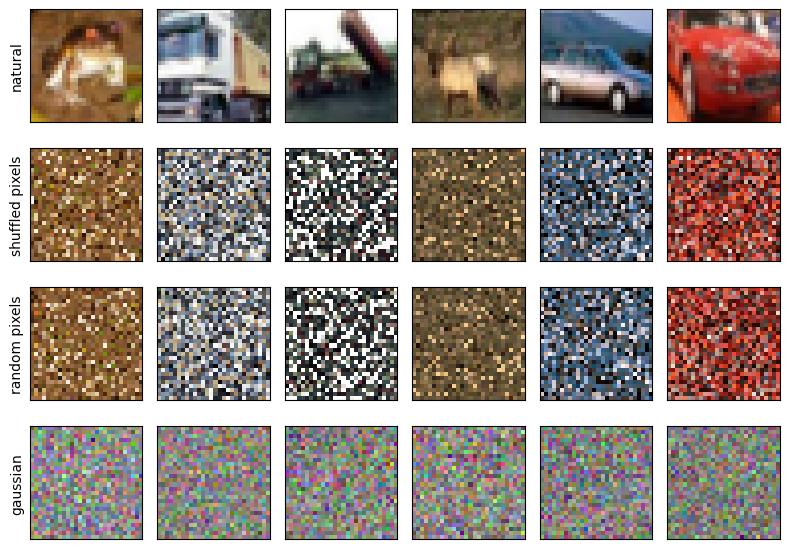

In [5]:
rows = []
for p in P_GRID:
    y = corrupt_labels(YTR_TRUE, p)
    rows.append({'p': p, 'measured fraction changed': (y != YTR_TRUE).float().mean().item(),
                 'expected 0.9p': 0.9 * p})
display(pd.DataFrame(rows).round(4))

fig, axes = plt.subplots(len(INPUT_CONDITIONS), 6, figsize=(8, 5.8))
for r, cond in enumerate(INPUT_CONDITIONS):
    xtr, _ = make_inputs(cond)
    for c in range(6):
        img = xtr[c].permute(1, 2, 0)
        img = (img - img.min()) / (img.max() - img.min() + 1e-8)   # stretched to [0,1] for display only
        axes[r, c].imshow(img.numpy())
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(cond.replace('_', ' '), fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'input_conditions.png'), dpi=150)
plt.show()
del xtr

## 4. Models

Built from Appendix A and Figure 3 of the paper. The cell below compares parameter counts against Table 1; all three should match exactly.

- **small Inception** (Figure 3): a conv module is convolution -> BN -> ReLU. The paper's count of 1,649,402 corresponds to convolutions without bias and batch norm with a learnable shift $\beta$ but no scale $\gamma$, which is TensorFlow's `batch_norm` default, so $\gamma$ is fixed to 1 here.
- **small AlexNet**: two blocks of (5x5 convolution -> 3x3 max-pool -> LRN), then fully connected layers of width 384 and 192 and a 10-way output. The paper does not give the number of conv channels; 64 (from the TensorFlow CIFAR-10 tutorial) gives exactly 1,387,786 parameters.
- **MLP 1x512**: one hidden layer of 512 units.

Initialization uses PyTorch defaults, since the paper does not report an initialization scheme.

In [6]:
class ConvModule(nn.Module):
    # convolution -> BN -> ReLU, with the BN gamma fixed to 1 (TF batch_norm default scale=False)
    def __init__(self, cin, cout, k, stride=1, bn=True):
        super().__init__()
        self.conv = nn.Conv2d(cin, cout, k, stride=stride, padding=k // 2, bias=not bn)
        self.bn = nn.BatchNorm2d(cout) if bn else None
        if bn:
            self.bn.weight.requires_grad_(False)

    def forward(self, x):
        x = self.conv(x)
        if self.bn is not None:
            x = self.bn(x)
        return F.relu(x)


class InceptionModule(nn.Module):
    # a 1x1 and a 3x3 branch, concatenated along channels
    def __init__(self, cin, ch1, ch3, bn=True):
        super().__init__()
        self.b1 = ConvModule(cin, ch1, 1, bn=bn)
        self.b3 = ConvModule(cin, ch3, 3, bn=bn)

    def forward(self, x):
        return torch.cat([self.b1(x), self.b3(x)], dim=1)


class DownsampleModule(nn.Module):
    # a stride-2 3x3 convolution and a 3x3 max-pool, concatenated along channels
    def __init__(self, cin, ch3, bn=True):
        super().__init__()
        self.conv = ConvModule(cin, ch3, 3, stride=2, bn=bn)
        self.pool = nn.MaxPool2d(3, stride=2, padding=1)

    def forward(self, x):
        return torch.cat([self.conv(x), self.pool(x)], dim=1)


class SmallInception(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, bn=True):
        super().__init__()
        self.features = nn.Sequential(
            ConvModule(3, 96, 3, bn=bn),                                         # 28x28x96
            InceptionModule(96, 32, 32, bn), InceptionModule(64, 32, 48, bn),    # -> 80
            DownsampleModule(80, 80, bn),                                        # 14x14x160
            InceptionModule(160, 112, 48, bn), InceptionModule(160, 96, 64, bn),
            InceptionModule(160, 80, 80, bn), InceptionModule(160, 48, 96, bn),  # -> 144
            DownsampleModule(144, 96, bn),                                       # 7x7x240
            InceptionModule(240, 176, 160, bn), InceptionModule(336, 176, 160, bn),  # -> 336
        )
        self.fc = nn.Linear(336, num_classes)

    def forward(self, x):
        x = self.features(x)
        return self.fc(x.mean(dim=(2, 3)))     # global average pooling over 7x7


class LRN(nn.Module):
    # LRN from the TF CIFAR-10 tutorial: depth_radius=4, bias=1, alpha=0.001/9, beta=0.75.
    # PyTorch divides alpha by the window size 9 internally, so pass 0.001. Computed in float32
    # to avoid overflow under mixed precision.
    def __init__(self):
        super().__init__()
        self.lrn = nn.LocalResponseNorm(size=9, alpha=0.001, beta=0.75, k=1.0)

    def forward(self, x):
        with torch.autocast(device_type=x.device.type, enabled=False):
            return self.lrn(x.float())


class SmallAlexNet(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 5, padding=2), nn.ReLU(), nn.MaxPool2d(3, 2, padding=1), LRN(),   # 14x14
            nn.Conv2d(64, 64, 5, padding=2), nn.ReLU(), nn.MaxPool2d(3, 2, padding=1), LRN(),  # 7x7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 7 * 7, 384), nn.ReLU(),
            nn.Linear(384, 192), nn.ReLU(), nn.Linear(192, num_classes))

    def forward(self, x):
        return self.classifier(self.features(x))


class MLP(nn.Module):
    def __init__(self, depth=1, width=512, in_dim=3 * 28 * 28, num_classes=NUM_CLASSES):
        super().__init__()
        layers, d = [nn.Flatten()], in_dim
        for _ in range(depth):
            layers += [nn.Linear(d, width), nn.ReLU()]
            d = width
        layers.append(nn.Linear(d, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def build_model(name):
    return {'inception': lambda: SmallInception(),
            'inception_nobn': lambda: SmallInception(bn=False),
            'alexnet': lambda: SmallAlexNet(),
            'mlp1x512': lambda: MLP(depth=1),
            'mlp3x512': lambda: MLP(depth=3)}[name]()


def n_params(model):
    return sum(q.numel() for q in model.parameters() if q.requires_grad)


PAPER_PARAMS = {'inception': 1649402, 'inception_nobn': 1649402, 'alexnet': 1387786,
                'mlp1x512': 1209866, 'mlp3x512': 1735178}
for name, ref in PAPER_PARAMS.items():
    m = build_model(name)
    out = m(torch.zeros(2, 3, 28, 28))
    ok = 'OK' if n_params(m) == ref else 'MISMATCH!'
    print(f'{name:15s} ours {n_params(m):>10,}   paper {ref:>10,}   {ok}   output {tuple(out.shape)}')

inception       ours  1,649,402   paper  1,649,402   OK   output (2, 10)
inception_nobn  ours  1,649,402   paper  1,649,402   OK   output (2, 10)
alexnet         ours  1,387,786   paper  1,387,786   OK   output (2, 10)
mlp1x512        ours  1,209,866   paper  1,209,866   OK   output (2, 10)
mlp3x512        ours  1,735,178   paper  1,735,178   OK   output (2, 10)


## 5. Training

- Optimizer: SGD with momentum 0.9 and no weight decay; the learning rate is multiplied by 0.95 after each epoch.
- At the end of every epoch, accuracy is computed in eval mode over the **whole training set** (using the labels the run was trained on) and the test set.
- The step at which training accuracy first reaches `FIT_ACC` is recorded as the "time to fit" used by Figure 1(b).
- Training stops when train accuracy reaches `STOP_ACC`, or it has not improved for `PLATEAU_PATIENCE` epochs, or `MAX_EPOCHS` is reached.
- Each finished experiment is saved as a json. While running, a checkpoint is written every `CKPT_EVERY` epochs, so a disconnect resumes automatically.

In [7]:
AMP_ON = USE_AMP and DEVICE.type == 'cuda'


def run_name(model_name, inputs, p):
    return f'{model_name}__{inputs}__p{p:.1f}'


def save_json(obj, path):
    tmp = path + '.tmp'
    with open(tmp, 'w') as f:
        json.dump(obj, f)
    os.replace(tmp, path)


_INPUT_CACHE = {}
def get_inputs(condition):
    if condition not in _INPUT_CACHE:
        _INPUT_CACHE.clear()                  # cache one condition at a time to save memory
        _INPUT_CACHE[condition] = make_inputs(condition)
    return _INPUT_CACHE[condition]


@torch.no_grad()
def evaluate(model, x, y):
    model.eval()
    loss_sum, correct = 0.0, 0
    for i in range(0, len(x), EVAL_BATCH):
        xb, yb = x[i:i + EVAL_BATCH], y[i:i + EVAL_BATCH]
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP_ON):
            out = model(xb)
        loss_sum += F.cross_entropy(out.float(), yb, reduction='sum').item()
        correct += (out.argmax(1) == yb).sum().item()
    return loss_sum / len(x), correct / len(x)


def run_experiment(model_name, inputs='natural', p=0.0):
    name = run_name(model_name, inputs, p)
    res_path = os.path.join(RESULT_DIR, name + '.json')
    ckpt_path = os.path.join(CKPT_DIR, name + '.pt')
    if os.path.exists(res_path):
        print(f'[skip] {name} already finished')
        with open(res_path) as f:
            return json.load(f)

    # ---- data ----
    xtr, xte = get_inputs(inputs)
    ytr = corrupt_labels(YTR_TRUE, p)
    frac_changed = (ytr != YTR_TRUE).float().mean().item()
    conv = not model_name.startswith('mlp')
    use_cl = conv and DEVICE.type == 'cuda'          # channels_last is faster for convnets on GPU
    def to_dev(x):
        x = x.to(DEVICE)
        return x.contiguous(memory_format=torch.channels_last) if use_cl else x
    xtr_d, xte_d = to_dev(xtr), to_dev(xte)
    ytr_d, yte_d = ytr.to(DEVICE), YTE.to(DEVICE)
    n = len(xtr_d)

    # ---- model and optimizer ----
    torch.manual_seed(MODEL_SEED)
    model = build_model(model_name).to(DEVICE)
    if use_cl:
        model = model.to(memory_format=torch.channels_last)
    lr0 = LR0[model_name]
    opt = torch.optim.SGD([q for q in model.parameters() if q.requires_grad],
                          lr=lr0, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
    scaler = torch.amp.GradScaler('cuda', enabled=AMP_ON)

    state = dict(epoch=0, step=0, epoch_log=[], step_log=[], fit_step=None, fit_epoch=None,
                 best_train_acc=0.0, epochs_since_best=0, status='running', train_time=0.0)
    if os.path.exists(ckpt_path):
        ck = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck['model'])
        opt.load_state_dict(ck['opt'])
        scaler.load_state_dict(ck['scaler'])
        state = ck['state']
        print(f'[resume] {name} continuing from epoch {state["epoch"]}')
    else:
        print(f'[start] {name} | {n_params(model):,} params | fraction of labels changed {frac_changed:.4f}')

    run_loss, run_count = torch.zeros((), device=DEVICE), 0
    while state['epoch'] < MAX_EPOCHS and state['status'] == 'running':
        epoch = state['epoch']
        lr = lr0 * LR_DECAY ** epoch
        for group in opt.param_groups:
            group['lr'] = lr

        # ---- one epoch of training ----
        model.train()
        t0 = time.time()
        g = torch.Generator().manual_seed(MODEL_SEED * 100003 + epoch)   # batch order survives a resume
        order = torch.randperm(n, generator=g).to(DEVICE)
        for i in range(0, n, BATCH_SIZE):
            idx = order[i:i + BATCH_SIZE]
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP_ON):
                loss = F.cross_entropy(model(xtr_d[idx]), ytr_d[idx])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            state['step'] += 1
            run_loss += loss.detach().float()
            run_count += 1
            if state['step'] % LOG_EVERY == 0:
                state['step_log'].append([state['step'], run_loss.item() / run_count])
                run_loss.zero_()
                run_count = 0
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        epoch_time = time.time() - t0
        state['train_time'] += epoch_time

        # ---- evaluation ----
        tr_loss, tr_acc = evaluate(model, xtr_d, ytr_d)
        te_loss, te_acc = evaluate(model, xte_d, yte_d)
        state['epoch'] += 1
        state['epoch_log'].append(dict(epoch=state['epoch'], step=state['step'], lr=lr,
                                       train_loss=tr_loss, train_acc=tr_acc,
                                       test_loss=te_loss, test_acc=te_acc,
                                       train_time=state['train_time']))
        if state['fit_step'] is None and tr_acc >= FIT_ACC:
            state['fit_step'], state['fit_epoch'] = state['step'], state['epoch']
        if tr_acc > state['best_train_acc'] + 1e-4:
            state['best_train_acc'], state['epochs_since_best'] = tr_acc, 0
        else:
            state['epochs_since_best'] += 1
        print(f'{name} | epoch {state["epoch"]:3d} | step {state["step"]:6d} | lr {lr:.4f} | '
              f'train loss {tr_loss:.4f} acc {tr_acc:.4f} | test acc {te_acc:.4f} | {epoch_time:.1f}s')

        if not math.isfinite(tr_loss):
            state['status'] = 'diverged'
        elif tr_acc >= STOP_ACC:
            state['status'] = 'converged'
        elif state['epochs_since_best'] >= PLATEAU_PATIENCE:
            state['status'] = 'plateau'
        if state['status'] == 'running' and state['epoch'] % CKPT_EVERY == 0:
            tmp = ckpt_path + '.tmp'
            torch.save(dict(model=model.state_dict(), opt=opt.state_dict(),
                            scaler=scaler.state_dict(), state=state), tmp)
            os.replace(tmp, ckpt_path)
    if state['status'] == 'running':
        state['status'] = 'max_epochs'

    last = state['epoch_log'][-1]
    result = dict(name=name, model=model_name, inputs=inputs, p=p, n_params=n_params(model),
                  frac_labels_changed=frac_changed, status=state['status'],
                  epochs=state['epoch'], steps=state['step'],
                  fit_step=state['fit_step'], fit_epoch=state['fit_epoch'],
                  final_train_acc=last['train_acc'], final_test_acc=last['test_acc'],
                  train_time_sec=state['train_time'],
                  epoch_log=state['epoch_log'], step_log=state['step_log'],
                  config=dict(batch_size=BATCH_SIZE, lr0=lr0, momentum=MOMENTUM, lr_decay=LR_DECAY,
                              weight_decay=WEIGHT_DECAY, max_epochs=MAX_EPOCHS, fit_acc=FIT_ACC,
                              stop_acc=STOP_ACC, plateau_patience=PLATEAU_PATIENCE,
                              data_seed=DATA_SEED, model_seed=MODEL_SEED, amp=AMP_ON,
                              device=torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'cpu'))
    save_json(result, res_path)
    if os.path.exists(ckpt_path):
        os.remove(ckpt_path)
    print(f'[done] {name} | {state["status"]} | train acc {last["train_acc"]:.4f} | '
          f'test acc {last["test_acc"]:.4f} | {state["train_time"] / 60:.1f} min')
    del model, opt, xtr_d, xte_d
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return result

## 6. Run all experiments

Order: the fast MLP and AlexNet runs over all $p$ first, then Inception at $p=0$ and $p=1$ and the three input conditions needed for Figure 1(a), then the remaining Inception values of $p$. That way Figure 1(a) can be drawn even if you run out of time partway through.

There are $3\times 11 + 3 = 36$ experiments in total (21 with `QUICK=True`). MLP and AlexNet usually take a few minutes each; Inception is much slower, and the random-label runs need tens of epochs. The number of seconds at the end of each line is the training time of that epoch, which lets you estimate the total. Free Colab limits how long a single session lasts; if it disconnects, just *Run all* again and it picks up where it stopped.

If an experiment ends with status `plateau` or `max_epochs`, it did not reach `STOP_ACC` under the current settings. Report that as it is (in the paper's Table 1 the MLP only reaches 99.34% on random labels).

In [8]:
def experiment_list():
    exps = [(m, 'natural', p) for m in MODELS if m != 'inception' for p in P_GRID]
    if 'inception' in MODELS:
        exps += [('inception', 'natural', 0.0), ('inception', 'natural', 1.0)]
        exps += [('inception', c, 0.0) for c in FIG1A_INPUTS]
        exps += [('inception', 'natural', p) for p in P_GRID if p not in (0.0, 1.0)]
    return exps


EXPERIMENTS = experiment_list()
done = sum(os.path.exists(os.path.join(RESULT_DIR, run_name(*e) + '.json')) for e in EXPERIMENTS)
print(f'{len(EXPERIMENTS)} experiments in total, {done} already finished')

for i, (m, inp, p) in enumerate(EXPERIMENTS, 1):
    print(f'\n===== [{i}/{len(EXPERIMENTS)}] {run_name(m, inp, p)} =====')
    run_experiment(m, inp, p)

36 experiments in total, 0 already finished

===== [1/36] mlp1x512__natural__p0.0 =====
[start] mlp1x512__natural__p0.0 | 1,209,866 params | fraction of labels changed 0.0000
mlp1x512__natural__p0.0 | epoch   1 | step    391 | lr 0.0100 | train loss 1.4302 acc 0.4953 | test acc 0.4585 | 1.1s
mlp1x512__natural__p0.0 | epoch   2 | step    782 | lr 0.0095 | train loss 1.2757 acc 0.5539 | test acc 0.4834 | 0.7s
mlp1x512__natural__p0.0 | epoch   3 | step   1173 | lr 0.0090 | train loss 1.1602 acc 0.5945 | test acc 0.4969 | 0.7s
mlp1x512__natural__p0.0 | epoch   4 | step   1564 | lr 0.0086 | train loss 1.0786 acc 0.6209 | test acc 0.5068 | 0.7s
mlp1x512__natural__p0.0 | epoch   5 | step   1955 | lr 0.0081 | train loss 1.0128 acc 0.6487 | test acc 0.5004 | 0.7s
mlp1x512__natural__p0.0 | epoch   6 | step   2346 | lr 0.0077 | train loss 0.9168 acc 0.6874 | test acc 0.5131 | 0.7s
mlp1x512__natural__p0.0 | epoch   7 | step   2737 | lr 0.0074 | train loss 0.8318 acc 0.7197 | test acc 0.5134 | 0.7s

## 7. Figure 1

This cell only reads the saved results, so it can be run on its own. Figures are written to `figures/`: `figure1.pdf` with all three panels together, and `figure1a.pdf`, `figure1b.pdf`, `figure1c.pdf` as separate panels for use with `subfigure` in LaTeX.

loaded 36 finished experiments


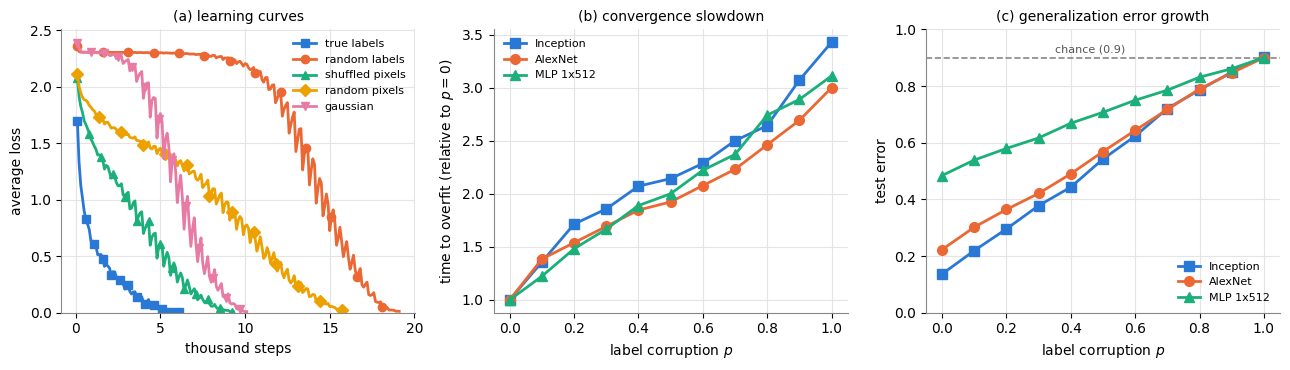

figures saved to /content/drive/MyDrive/zhang2017_repro/figures


In [9]:
def load_results():
    out = {}
    for path in sorted(glob.glob(os.path.join(RESULT_DIR, '*.json'))):
        with open(path) as f:
            r = json.load(f)
        out[(r['model'], r['inputs'], round(r['p'], 1))] = r
    return out


R = load_results()
print(f'loaded {len(R)} finished experiments')

COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']   # blue, orange, aqua, yellow, magenta
MODEL_STYLE = {'inception': ('Inception', COLORS[0], 's'),
               'alexnet': ('AlexNet', COLORS[1], 'o'),
               'mlp1x512': ('MLP 1x512', COLORS[2], '^')}
FIG1A_RUNS = [('true labels', 'natural', 0.0, 's'), ('random labels', 'natural', 1.0, 'o'),
              ('shuffled pixels', 'shuffled_pixels', 0.0, '^'), ('random pixels', 'random_pixels', 0.0, 'D'),
              ('gaussian', 'gaussian', 0.0, 'v')]
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e4e4', 'grid.linewidth': 0.8,
                     'axes.edgecolor': '#888888', 'legend.frameon': False})


def panel_a(ax):
    for (label, inp, p, marker), color in zip(FIG1A_RUNS, COLORS):
        r = R.get(('inception', inp, p))
        if r is None or len(r['step_log']) == 0:
            continue
        s = np.array(r['step_log'])
        ax.plot(s[:, 0] / 1000, s[:, 1], color=color, lw=2, marker=marker, ms=6,
                markevery=max(1, len(s) // 12), label=label)
    ax.set_xlabel('thousand steps'); ax.set_ylabel('average loss')
    ax.set_ylim(bottom=0); ax.set_title('(a) learning curves', fontsize=10)
    if ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=8)


def model_curve(model, value_fn):
    ps, vals = [], []
    for p in P_GRID:
        r = R.get((model, 'natural', p))
        v = None if r is None else value_fn(model, r)
        if v is not None:
            ps.append(p); vals.append(v)
    return ps, vals


def rel_fit_time(model, r):
    base = R.get((model, 'natural', 0.0))
    if base is None or base['fit_step'] is None or r['fit_step'] is None:
        return None
    return r['fit_step'] / base['fit_step']


def panel_b(ax):
    for model, (label, color, marker) in MODEL_STYLE.items():
        ps, vals = model_curve(model, rel_fit_time)
        if ps:
            ax.plot(ps, vals, color=color, lw=2, marker=marker, ms=7, label=label)
    ax.set_xlabel('label corruption $p$'); ax.set_ylabel('time to overfit (relative to $p=0$)')
    ax.set_title('(b) convergence slowdown', fontsize=10)
    if ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=8)
    else:
        ax.text(0.5, 0.5, 'no run has reached FIT_ACC yet', transform=ax.transAxes,
                ha='center', color='#555555', fontsize=9)


def panel_c(ax):
    ax.axhline(0.9, color='#888888', ls='--', lw=1.2)
    ax.text(0.35, 0.91, 'chance (0.9)', color='#555555', fontsize=8, va='bottom')
    for model, (label, color, marker) in MODEL_STYLE.items():
        ps, vals = model_curve(model, lambda m, r: 1 - r['final_test_acc'])
        if ps:
            ax.plot(ps, vals, color=color, lw=2, marker=marker, ms=7, label=label)
    ax.set_xlabel('label corruption $p$'); ax.set_ylabel('test error')
    ax.set_ylim(0, 1); ax.set_title('(c) generalization error growth', fontsize=10)
    if ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=8, loc='lower right')


fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for fn, ax in zip((panel_a, panel_b, panel_c), axes):
    fn(ax)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'figure1.pdf')); fig.savefig(os.path.join(FIG_DIR, 'figure1.png'), dpi=200)
plt.show()

for tag, fn in (('a', panel_a), ('b', panel_b), ('c', panel_c)):
    f, ax = plt.subplots(figsize=(4.4, 3.6))
    fn(ax)
    f.tight_layout()
    f.savefig(os.path.join(FIG_DIR, f'figure1{tag}.pdf'))
    plt.close(f)
print('figures saved to', FIG_DIR)

## 8. Result tables

- `results_all.csv`: one row per experiment, with the measured fraction of changed labels, final train and test accuracy, the step at which the run was fitted and the relative time, the stopping reason and the training time.
- Two LaTeX tables are printed below, `tab:results` (results for the three models at each $p$) and `tab:setup` (the paper's settings against ours), ready to paste into the report.

In [10]:
R = load_results()
MODEL_ORDER = ['inception', 'alexnet', 'mlp1x512']
rows = []
for (m, inp, p), r in R.items():
    rel = rel_fit_time(m, r) if inp == 'natural' else None
    rows.append(dict(model=m, inputs=inp, p=p,
                     labels_changed=round(r['frac_labels_changed'], 4), expected_0_9p=round(0.9 * p, 4),
                     train_acc=round(r['final_train_acc'], 4), test_acc=round(r['final_test_acc'], 4),
                     test_error=round(1 - r['final_test_acc'], 4),
                     fit_epoch=r['fit_epoch'], fit_step=r['fit_step'],
                     rel_fit_time=None if rel is None else round(rel, 2),
                     epochs=r['epochs'], status=r['status'], train_min=round(r['train_time_sec'] / 60, 1)))
df = pd.DataFrame(rows)
if len(df):
    df['_m'] = df['model'].map({m: i for i, m in enumerate(MODEL_ORDER)})
    df = df.sort_values(['_m', 'inputs', 'p']).drop(columns='_m').reset_index(drop=True)
    df.to_csv(os.path.join(ROOT, 'results_all.csv'), index=False)
    display(df)


def fmt(v, digits=2, pct=False):
    if v is None or (isinstance(v, float) and math.isnan(v)):
        return '--'
    return f'{100 * v:.{digits}f}' if pct else f'{v:.{digits}f}'


lines = [r'\begin{table}[t]', r'\centering', r'\small',
         r"\caption{Our results on CIFAR-10. ``Changed'' is the measured fraction of training labels that differ "
         r"from the truth (expected $0.9p$). Test error is in percent after training stops; ``relative time'' is "
         r"the number of steps until training accuracy first reaches " + f'{100 * FIT_ACC:g}' + r"\%, divided by the same number at $p=0$.}",
         r'\label{tab:results}',
         r'\begin{tabular}{ccc ccc ccc}', r'\toprule',
         r' & & & \multicolumn{3}{c}{Test error (\%)} & \multicolumn{3}{c}{Relative time} \\',
         r'\cmidrule(lr){4-6}\cmidrule(lr){7-9}',
         r'$p$ & Changed & $0.9p$ & Inception & AlexNet & MLP & Inception & AlexNet & MLP \\', r'\midrule']
for p in P_GRID:
    rs = [R.get((m, 'natural', p)) for m in MODEL_ORDER]
    changed = next((r['frac_labels_changed'] for r in rs if r is not None), None)
    errs = [fmt(None if r is None else 1 - r['final_test_acc'], 2, pct=True) for r in rs]
    rels = [fmt(None if r is None else rel_fit_time(m, r), 2) for m, r in zip(MODEL_ORDER, rs)]
    lines.append(f'{p:.1f} & {fmt(changed, 4)} & {0.9 * p:.2f} & ' + ' & '.join(errs + rels) + r' \\')
lines += [r'\bottomrule', r'\end{tabular}', r'\end{table}']
print('\n'.join(lines))

,model,inputs,p,labels_changed,expected_0_9p,train_acc,test_acc,test_error,fit_epoch,fit_step,rel_fit_time,epochs,status,train_min
0,inception,gaussian,0.0,0.0000,0.00,0.9998,0.1021,0.8979,26,10166,NaN,26,converged,4.0
1,inception,natural,0.0,0.0000,0.00,0.9999,0.8635,0.1365,14,5474,1.00,16,converged,2.5
2,inception,natural,0.1,0.0918,0.09,0.9999,0.7809,0.2191,19,7429,1.36,21,converged,3.3
3,inception,natural,0.2,0.1829,0.18,0.9996,0.7044,0.2956,24,9384,1.71,24,converged,3.7
4,inception,natural,0.3,0.2722,0.27,0.9997,0.6221,0.3779,26,10166,1.86,27,converged,4.2
5,inception,natural,0.4,0.3604,0.36,1.0000,0.5568,0.4432,29,11339,2.07,30,converged,4.6
6,inception,natural,0.5,0.4519,0.45,0.9996,0.4577,0.5423,30,11730,2.14,31,converged,4.8
7,inception,natural,0.6,0.5441,0.54,0.9994,0.3767,0.6233,32,12512,2.29,33,converged,5.1
8,inception,natural,0.7,0.6328,0.63,0.9994,0.2795,0.7205,35,13685,2.50,36,converged,5.6
9,inception,natural,0.8,0.7219,0.72,0.9994,0.2139,0.7861,37,14467,2.64,38,converged,5.9


\begin{table}[t]
\centering
\small
\caption{Our results on CIFAR-10. ``Changed'' is the measured fraction of training labels that differ from the truth (expected $0.9p$). Test error is in percent after training stops; ``relative time'' is the number of steps until training accuracy first reaches 99\%, divided by the same number at $p=0$.}
\label{tab:results}
\begin{tabular}{ccc ccc ccc}
\toprule
 & & & \multicolumn{3}{c}{Test error (\%)} & \multicolumn{3}{c}{Relative time} \\
\cmidrule(lr){4-6}\cmidrule(lr){7-9}
$p$ & Changed & $0.9p$ & Inception & AlexNet & MLP & Inception & AlexNet & MLP \\
\midrule
0.0 & 0.0000 & 0.00 & 13.65 & 22.28 & 48.42 & 1.00 & 1.00 & 1.00 \\
0.1 & 0.0918 & 0.09 & 21.91 & 30.18 & 53.87 & 1.36 & 1.38 & 1.22 \\
0.2 & 0.1829 & 0.18 & 29.56 & 36.43 & 57.96 & 1.71 & 1.54 & 1.48 \\
0.3 & 0.2722 & 0.27 & 37.79 & 42.10 & 61.67 & 1.86 & 1.69 & 1.67 \\
0.4 & 0.3604 & 0.36 & 44.32 & 49.01 & 66.86 & 2.07 & 1.85 & 1.89 \\
0.5 & 0.4519 & 0.45 & 54.23 & 56.86 & 70.73 & 2.14 

In [11]:
gpu = torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'
setup_rows = [
    ('Optimizer', 'SGD, momentum 0.9', 'same'),
    ('Initial learning rate', '0.1 (Inception), 0.01 (AlexNet, MLP)', 'same'),
    ('Learning-rate schedule', r'$\times 0.95$ per epoch', 'same'),
    ('Batch size', 'not reported', f'{BATCH_SIZE}'),
    ('Number of epochs', 'not reported',
     f'until train acc $\\geq$ {100 * STOP_ACC:g}\\%, no gain for {PLATEAU_PATIENCE} epochs, or {MAX_EPOCHS} epochs'),
    ('``Fitted\'\' criterion (Fig.~1b)', 'not reported', f'first epoch with train acc $\\geq$ {100 * FIT_ACC:g}\\%'),
    ('Preprocessing', r'$/255$, center crop $28{\times}28$, per-image whitening', 'same'),
    ('Explicit regularization', 'none (no weight decay, dropout, augmentation)', 'same'),
    ('Batch norm (Inception)', 'yes (Figure 3)', r'conv without bias; BN with learnable shift $\beta$ only ($\gamma=1$), which reproduces the 1,649,402 parameters'),
    ('AlexNet conv channels', 'not reported', '64, 64 (matches 1,387,786 params)'),
    ('Initialization', 'not reported', 'PyTorch defaults'),
    ('Precision / hardware', 'not reported', f'mixed precision (fp16) on {gpu}' if AMP_ON else f'fp32 on {gpu}'),
    ('Seeds', 'not reported', f'data seed {DATA_SEED}, model seed {MODEL_SEED}; one run per setting'),
]
lines = [r'\begin{table}[t]', r'\centering', r'\small',
         r'\caption{Training setup: what the paper reports (Appendix A) and what we use.}', r'\label{tab:setup}',
         r'\begin{tabular}{p{0.24\linewidth}p{0.33\linewidth}p{0.33\linewidth}}', r'\toprule',
         r'Item & Paper & Ours \\', r'\midrule']
lines += [f'{a} & {b} & {c} \\\\' for a, b, c in setup_rows]
lines += [r'\bottomrule', r'\end{tabular}', r'\end{table}']
print('\n'.join(lines))

\begin{table}[t]
\centering
\small
\caption{Training setup: what the paper reports (Appendix A) and what we use.}
\label{tab:setup}
\begin{tabular}{p{0.24\linewidth}p{0.33\linewidth}p{0.33\linewidth}}
\toprule
Item & Paper & Ours \\
\midrule
Optimizer & SGD, momentum 0.9 & same \\
Initial learning rate & 0.1 (Inception), 0.01 (AlexNet, MLP) & same \\
Learning-rate schedule & $\times 0.95$ per epoch & same \\
Batch size & not reported & 128 \\
Number of epochs & not reported & until train acc $\geq$ 99.9\%, no gain for 15 epochs, or 100 epochs \\
``Fitted'' criterion (Fig.~1b) & not reported & first epoch with train acc $\geq$ 99\% \\
Preprocessing & $/255$, center crop $28{\times}28$, per-image whitening & same \\
Explicit regularization & none (no weight decay, dropout, augmentation) & same \\
Batch norm (Inception) & yes (Figure 3) & conv without bias; BN with learnable shift $\beta$ only ($\gamma=1$), which reproduces the 1,649,402 parameters \\
AlexNet conv channels & not reported 

In [1]:
import os, sys, platform, subprocess, torch
print('CPU     :', subprocess.getoutput("lscpu | grep 'Model name:' | head -1").split(':', 1)[1].strip())
print('Cores   :', os.cpu_count())
print('RAM     :', subprocess.getoutput("free -g | awk '/^Mem:/{print $2}'"), 'GB')
print('GPU     :', torch.cuda.get_device_name(0),
      f'({torch.cuda.get_device_properties(0).total_memory / 1e9:.0f} GB)')
print('Driver  :', subprocess.getoutput('nvidia-smi --query-gpu=driver_version --format=csv,noheader'))
print('OS      :', platform.platform())
print('Python  :', sys.version.split()[0])
print('PyTorch :', torch.__version__, '| CUDA', torch.version.cuda)

CPU     : Intel(R) Xeon(R) CPU @ 2.00GHz
Cores   : 2
RAM     : 12 GB
GPU     : Tesla T4 (16 GB)
Driver  : 580.82.07
OS      : Linux-6.6.122+-x86_64-with-glibc2.39
Python  : 3.13.15
PyTorch : 2.11.0+cu130 | CUDA 13.0


In [7]:
import json, glob
RESULTS_DIR = '/content/drive/MyDrive/zhang2017_repro/results'
R = {}
for f in glob.glob(RESULTS_DIR + '/*natural*.json'):
    d = json.load(open(f)); R[(d['model'], round(d['p'], 1))] = d
assert len(R) == 33, f'found {len(R)} runs, expected 33 -- check RESULTS_DIR'
models = ['inception', 'alexnet', 'mlp1x512']
ps = [round(0.1 * i, 1) for i in range(11)]

def first_epoch(d, key, cond):
    for e in d['epoch_log']:
        if cond(e[key]): return e['epoch']
    return None

crit = {
  'acc>=99%':   ('train_acc', lambda v: v >= 0.99),
  'acc>=99.5%': ('train_acc', lambda v: v >= 0.995),
  'acc>=99.9%': ('train_acc', lambda v: v >= 0.999),
  'loss<=0.05': ('train_loss', lambda v: v <= 0.05),
  'loss<=0.02': ('train_loss', lambda v: v <= 0.02),
}
for name, (key, cond) in crit.items():
    print(f'\n== {name}: relative time to fit (epochs; * = never reached, censored at last epoch)')
    print('p    ' + ''.join(f'{m:>12}' for m in models))
    base = {m: first_epoch(R[(m, 0.0)], key, cond) for m in models}
    print('p0 epochs', base)
    if None in base.values():
        print('  skipped: some p=0 run never meets this criterion'); continue
    for p in ps:
        row = ''
        for m in models:
            d = R[(m, p)]; e = first_epoch(d, key, cond)
            if e is None: row += f"{d['epochs'] / base[m]:>11.2f}*"
            else: row += f'{e / base[m]:>12.2f}'
        print(f'{p:<5}' + row)


== acc>=99%: relative time to fit (epochs; * = never reached, censored at last epoch)
p       inception     alexnet    mlp1x512
p0 epochs {'inception': 14, 'alexnet': 13, 'mlp1x512': 27}
0.0          1.00        1.00        1.00
0.1          1.36        1.38        1.22
0.2          1.71        1.54        1.48
0.3          1.86        1.69        1.67
0.4          2.07        1.85        1.89
0.5          2.14        1.92        2.00
0.6          2.29        2.08        2.22
0.7          2.50        2.23        2.37
0.8          2.64        2.46        2.74
0.9          3.07        2.69        2.89
1.0          3.43        3.00        3.11

== acc>=99.5%: relative time to fit (epochs; * = never reached, censored at last epoch)
p       inception     alexnet    mlp1x512
p0 epochs {'inception': 14, 'alexnet': 15, 'mlp1x512': 31}
0.0          1.00        1.00        1.00
0.1          1.43        1.20        1.23
0.2          1.71        1.33        1.55
0.3          1.86        1.47     

In [5]:
import json, glob
RESULTS_DIR = '/content/drive/MyDrive/zhang2017_repro/results'
R = {}
for f in glob.glob(RESULTS_DIR + '/*natural*.json'):
    d = json.load(open(f)); R[(d['model'], round(d['p'], 1))] = d
assert len(R) == 33, f'found {len(R)} runs, expected 33 -- check RESULTS_DIR'
models = ['inception', 'alexnet', 'mlp1x512']
print('test error (%): min over training [epoch] | at 99% fit | at stop [epoch] | slope over last 5 epochs (pts/epoch)')
for m in models:
    print('\n' + m)
    for p in [round(0.1 * i, 1) for i in range(11)]:
        d = R[(m, p)]; L = d['epoch_log']
        err = [100 * (1 - e['test_acc']) for e in L]
        imin = min(range(len(err)), key=err.__getitem__)
        fit = err[d['fit_epoch'] - 1]
        slope = (err[-1] - err[-6]) / 5 if len(err) >= 6 else float('nan')
        print(f'  p={p:<4} min {err[imin]:6.2f} [{imin+1:3}] | fit {fit:6.2f} | stop {err[-1]:6.2f} [{len(err):3}] | {slope:+.3f}')

test error (%): min over training [epoch] | at 99% fit | at stop [epoch] | slope over last 5 epochs (pts/epoch)

inception
  p=0.0  min  13.65 [ 16] | fit  13.77 | stop  13.65 [ 16] | -1.320
  p=0.1  min  19.42 [  9] | fit  24.36 | stop  21.91 [ 21] | -0.928
  p=0.2  min  22.17 [  6] | fit  29.56 | stop  29.56 [ 24] | -1.190
  p=0.3  min  25.28 [  8] | fit  38.27 | stop  37.79 [ 27] | -0.668
  p=0.4  min  28.30 [  6] | fit  46.89 | stop  44.32 [ 30] | -0.844
  p=0.5  min  30.77 [  7] | fit  55.19 | stop  54.23 [ 31] | -0.930
  p=0.6  min  33.82 [ 10] | fit  65.66 | stop  62.33 [ 33] | -0.854
  p=0.7  min  39.18 [  8] | fit  71.36 | stop  72.05 [ 36] | -0.300
  p=0.8  min  46.40 [  8] | fit  79.19 | stop  78.61 [ 38] | -0.338
  p=0.9  min  61.78 [ 12] | fit  84.91 | stop  84.91 [ 43] | -0.218
  p=1.0  min  86.39 [  3] | fit  90.08 | stop  90.23 [ 49] | +0.014

alexnet
  p=0.0  min  22.28 [ 15] | fit  23.11 | stop  22.28 [ 15] | -0.210
  p=0.1  min  25.79 [  8] | fit  30.51 | stop  30.18

## 9. What to look at when writing the report

- **Figure 1(a)**: whether all five curves eventually approach zero; whether random labels are the slowest; whether random pixels and Gaussian converge faster than random labels (the observation in Section 2.1 of the paper).
- **Figure 1(b)**: whether the time to fit grows by only a small factor as $p$ increases. Note that our times are recorded per epoch (accuracy is checked once at the end of each epoch), so the resolution is one epoch.
- **Figure 1(c)**: whether the test error at $p=0$ is in the same range as Table 1 of the paper (without regularization, roughly 14% for Inception, 24% for AlexNet, 49% for MLP 1x512), and whether it approaches 90% at $p=1$.
- **The label-fraction table**: the measured fraction should be within about half a percentage point of $0.9p$.
- Every setting is run with a single seed, which should be stated in the report; the numbers carry some run-to-run variation.